<a href="https://colab.research.google.com/github/SyedAliRaza7865/MLE_CustomerSegmentation/blob/main/MLE_CaseStudy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [8]:
df = pd.read_csv("/content/online_retail_clean.csv")
print("Shape:", df.shape)


Shape: (391150, 9)


In [9]:
display(df.head())


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [10]:
display(df.tail())


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
391145,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France,10.20
391146,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,12.60
391147,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,16.60
391148,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,16.60
391149,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France,14.85


In [11]:
print(df.isna().sum())


InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64


In [13]:
# Convert InvoiceDate into date format
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Use the day after the last purchase as the reference date
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate Recency, Frequency and Monetary for each customer
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "Revenue": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]
display(rfm.head())
print("RFM Shape:", rfm.shape)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1437.24
12349,19,1,1457.55
12350,310,1,294.40


RFM Shape: (4334, 3)


In [14]:
print(rfm.isna().sum())


Recency      0
Frequency    0
Monetary     0
dtype: int64


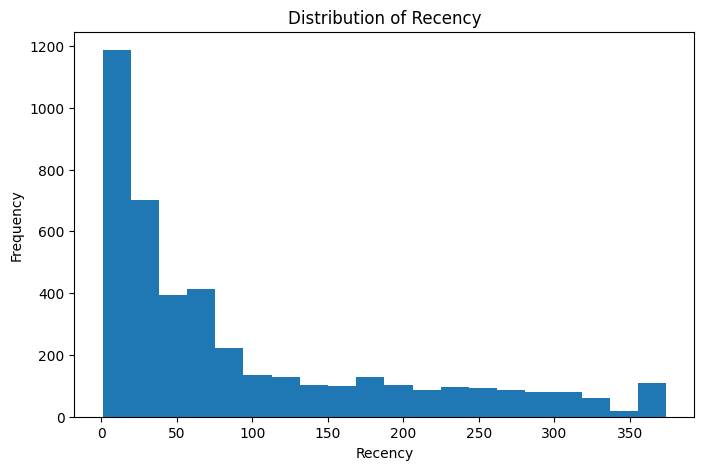

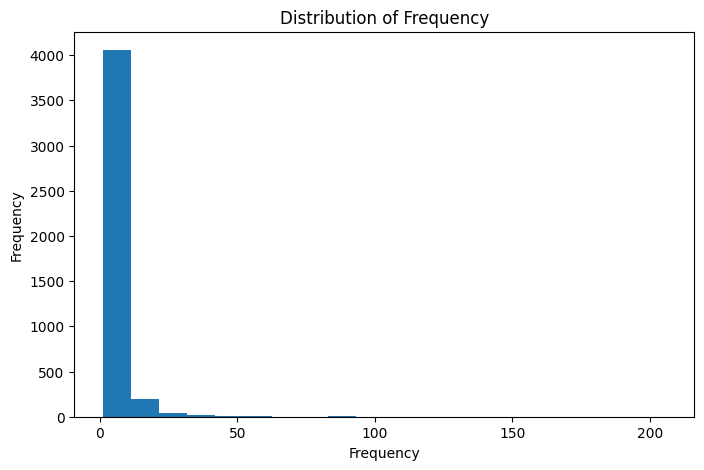

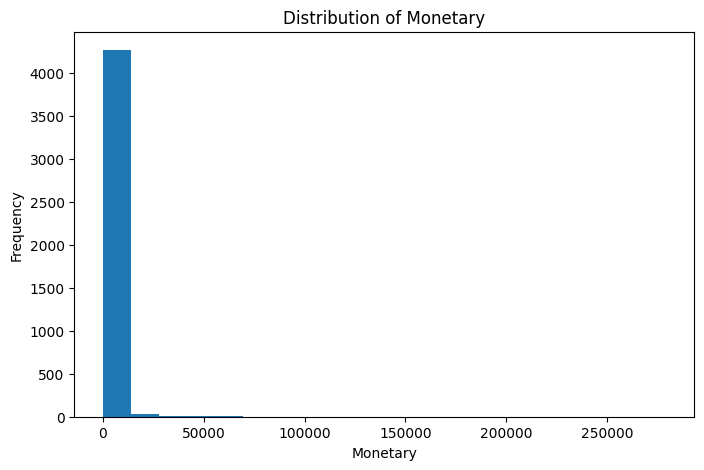

In [15]:
plt.figure(figsize=(8,5))
plt.hist(rfm["Recency"], bins=20)
plt.xlabel("Recency")
plt.ylabel("Frequency")
plt.title("Distribution of Recency")
plt.show()

plt.figure(figsize=(8,5))
plt.hist(rfm["Frequency"], bins=20)
plt.xlabel("Frequency")
plt.ylabel("Frequency")
plt.title("Distribution of Frequency")
plt.show()

plt.figure(figsize=(8,5))
plt.hist(rfm["Monetary"], bins=20)
plt.xlabel("Monetary")
plt.ylabel("Frequency")
plt.title("Distribution of Monetary")
plt.show()


In [16]:
X = rfm.copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [17]:
rows = []
models = {}

for k in range(2, 11):
    model = KMeans(n_clusters=k, init="random", random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    rows.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, labels)
    })

    models[k] = (model, labels)

scores = pd.DataFrame(rows)
display(scores.round(4))


,K,Inertia,Silhouette Score
0,2,9008.0513,0.8978
1,3,5434.3931,0.5940
2,4,4099.9286,0.6163
3,5,3635.9612,0.5013
4,6,2732.2452,0.5160
5,7,2406.9229,0.4817
6,8,2246.8052,0.4241
7,9,1595.6981,0.4269
8,10,1507.3039,0.4112


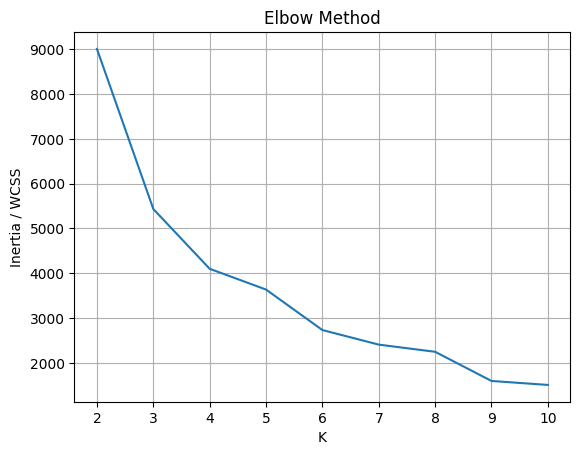

In [18]:
plt.plot(scores["K"], scores["Inertia"])
plt.xlabel("K")
plt.ylabel("Inertia / WCSS")
plt.title("Elbow Method")
plt.grid()
plt.show()


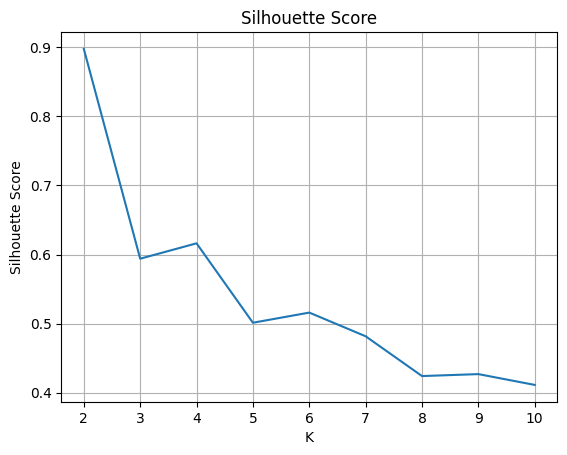

In [19]:
plt.plot(scores["K"], scores["Silhouette Score"])
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")
plt.grid()
plt.show()


In [21]:
# Select K after looking at the graphs
best_k = 3
model, labels = models[best_k]

rfm["KMeans_Cluster"] = labels
display(rfm["KMeans_Cluster"].value_counts().sort_index().to_frame("customers"))


,customers
KMeans_Cluster,
0,3225
1,25
2,1084


In [22]:
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

rfm["DBSCAN_Cluster"] = dbscan_labels
display(rfm["DBSCAN_Cluster"].value_counts().sort_index().to_frame("customers"))

# -1 means noise / outlier


,customers
DBSCAN_Cluster,
-1,55
0,4279


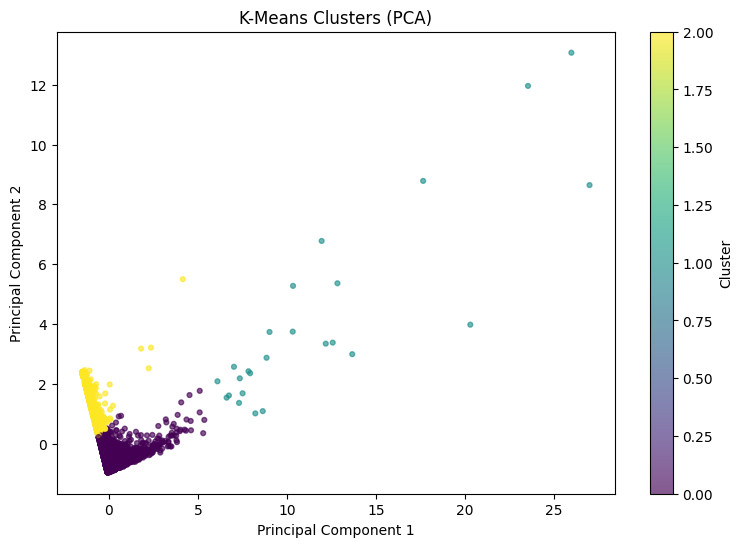

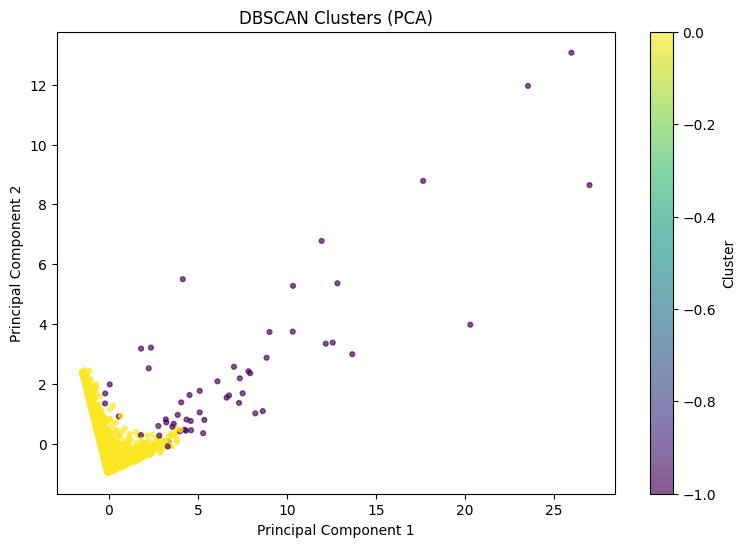

In [23]:
X_pca = PCA(n_components=2).fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, s=12, alpha=0.65)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters (PCA)")
plt.colorbar(sc, label="Cluster")
plt.show()

plt.figure(figsize=(9, 6))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, s=12, alpha=0.65)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clusters (PCA)")
plt.colorbar(sc, label="Cluster")
plt.show()


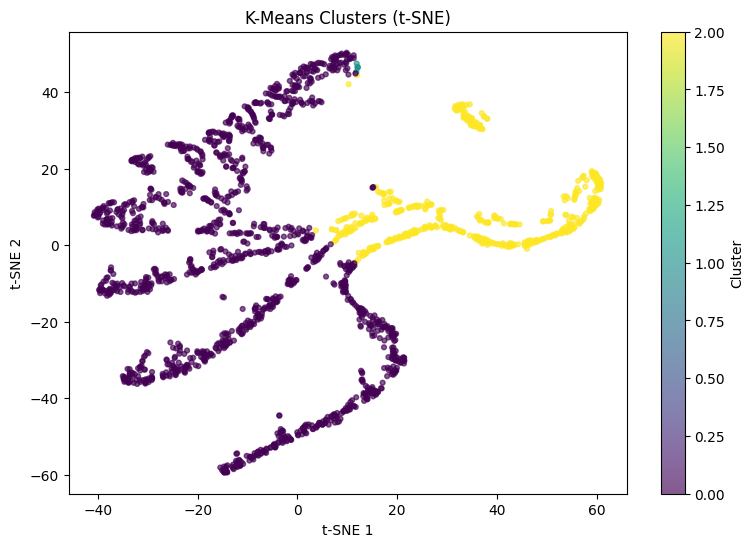

In [24]:
# Use a sample so t-SNE runs faster
sample_size = min(2000, len(X_scaled))
sample_indices = np.random.RandomState(42).choice(len(X_scaled), sample_size, replace=False)

X_sample = X_scaled[sample_indices]
labels_sample = labels[sample_indices]

X_tsne = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(X_sample)

plt.figure(figsize=(9, 6))
sc = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels_sample, s=12, alpha=0.65)
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("K-Means Clusters (t-SNE)")
plt.colorbar(sc, label="Cluster")
plt.show()


In [25]:
cluster_summary = rfm.groupby("KMeans_Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(2)
display(cluster_summary)


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,41.42,4.65,1833.64
1,6.12,67.84,85859.88
2,247.28,1.57,624.75


In [26]:
for cluster in cluster_summary.index:
    recency = cluster_summary.loc[cluster, "Recency"]
    frequency = cluster_summary.loc[cluster, "Frequency"]
    monetary = cluster_summary.loc[cluster, "Monetary"]

    if recency < rfm["Recency"].median() and frequency > rfm["Frequency"].median():
        print("Cluster", cluster, ": Loyal Customers")
        print("Marketing Action: Give loyalty points and special offers.\n")
    elif recency > rfm["Recency"].median():
        print("Cluster", cluster, ": At-Risk Customers")
        print("Marketing Action: Send reminders and win-back discounts.\n")
    elif monetary > rfm["Monetary"].median():
        print("Cluster", cluster, ": High-Spending Customers")
        print("Marketing Action: Offer premium products and bundles.\n")
    else:
        print("Cluster", cluster, ": Regular Customers")
        print("Marketing Action: Use product recommendations and discounts.\n")


Cluster 0 : Loyal Customers
Marketing Action: Give loyalty points and special offers.

Cluster 1 : Loyal Customers
Marketing Action: Give loyalty points and special offers.

Cluster 2 : At-Risk Customers
Marketing Action: Send reminders and win-back discounts.



In [27]:
rfm.to_csv("customer_segments_rfm.csv")
print("Customer segmentation file saved successfully.")


Customer segmentation file saved successfully.
